---
format:
  html:
    code-fold: true
    embed-resources: true
---

# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

**Discuss with your partner, and make notes here.** Precision is the percentage of people predicted to have the disease who actually have it; high precision means few false positives.

2. Explain what "recall" represents in this context.

**Discuss with your partner, and make notes here.** Recall is the percentage of people who have the disease that the model correctly identifies; high recall means few missed cases.

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

**Discuss with your partner, and make notes here.** Failing to diagnose someone who truly has the disease is more serious because it can delay needed treatment.

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

**Discuss with your partner, and make notes here.** I would prefer higher recall, because it reduces the number of true disease cases that are missed.

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

**Discuss with your partner, and make notes here.** The rule should be less strict, so that more people are classified as having the disease.

6. What is a downside to your choice in the previous part?

**Discuss with your partner, and make notes here.** The downside is more false positives, which lowers precision and can lead to unnecessary tests and anxiety.

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [3]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


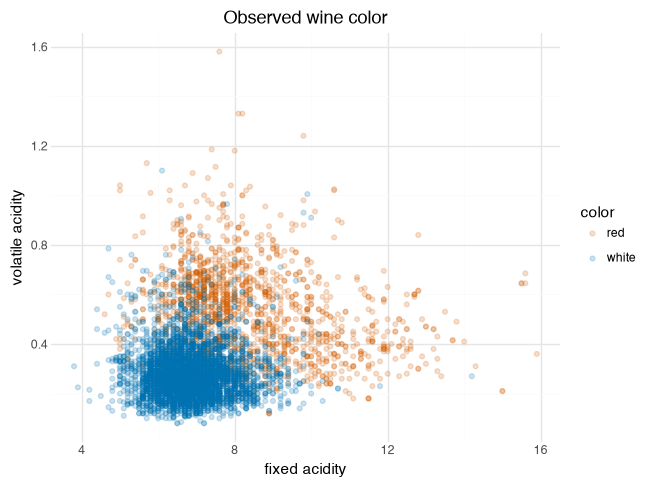

In [4]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

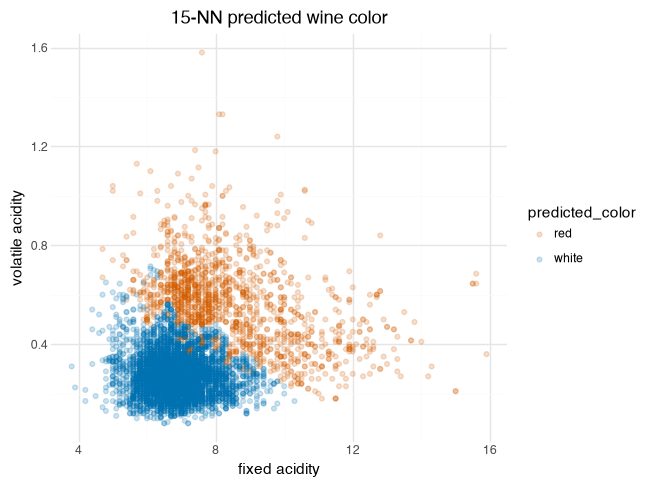

In [5]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

wine_features = ["fixed acidity", "volatile acidity"]
X_wine = df_train[wine_features]
y_wine = df_train["color"]
folds = StratifiedKFold(n_splits=10, shuffle=True, random_state=5544)

knn_wine = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=15))
])
knn_wine.fit(X_wine, y_wine)

predicted_knn = df_train.copy()
predicted_knn["predicted_color"] = knn_wine.predict(X_wine)
(
    ggplot(predicted_knn, aes(x="fixed acidity", y="volatile acidity", color="predicted_color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="15-NN predicted wine color")
    + theme_minimal()
)

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [7]:
scoring = {
    "Precision (macro)": "precision_macro",
    "Recall (macro)": "recall_macro",
    "F1 (macro)": "f1_macro"
}
knn_cv = cross_validate(knn_wine, X_wine, y_wine, cv=folds, scoring=scoring)
knn_scores = pd.Series({metric: knn_cv[f"test_{metric}"].mean() for metric in scoring}).round(3)
print("10-fold CV scores for 15-NN:")
print(knn_scores)

10-fold CV scores for 15-NN:
Precision (macro)    0.881
Recall (macro)       0.858
F1 (macro)           0.869
dtype: float64


3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

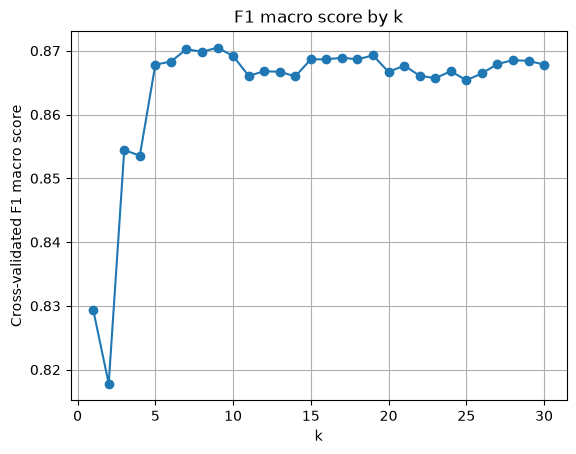

Best k: 9
Best CV F1 macro: 0.87


In [8]:
import matplotlib.pyplot as plt

knn_grid = GridSearchCV(
    Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())]),
    {"knn__n_neighbors": range(1, 31)},
    cv=folds, scoring="f1_macro"
)
knn_grid.fit(X_wine, y_wine)
grid_results = pd.DataFrame(knn_grid.cv_results_)
plt.plot(grid_results["param_knn__n_neighbors"], grid_results["mean_test_score"], marker="o")
plt.xlabel("k")
plt.ylabel("Cross-validated F1 macro score")
plt.title("F1 macro score by k")
plt.grid()
plt.show()
print("Best k:", knn_grid.best_params_["knn__n_neighbors"])
print("Best CV F1 macro:", round(knn_grid.best_score_, 3))

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.


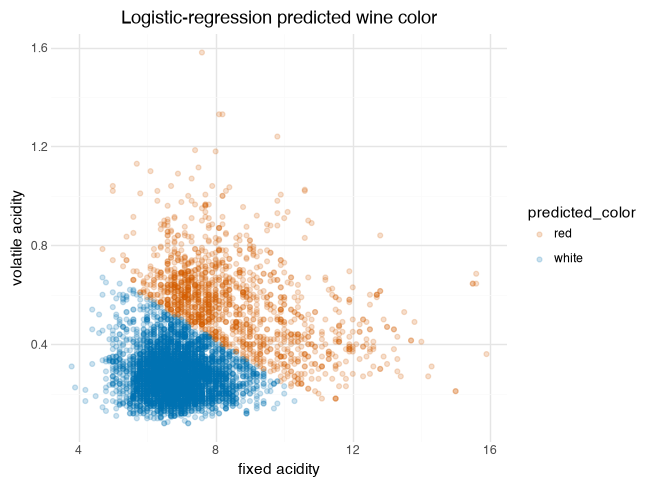

In [9]:
from sklearn.linear_model import LogisticRegression

logistic_two = LogisticRegression(penalty=None, max_iter=5000)
logistic_two.fit(X_wine, y_wine)

predicted_logistic = df_train.copy()
predicted_logistic["predicted_color"] = logistic_two.predict(X_wine)
(
    ggplot(predicted_logistic, aes(x="fixed acidity", y="volatile acidity", color="predicted_color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Logistic-regression predicted wine color")
    + theme_minimal()
)

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [10]:
logistic_two_cv = cross_validate(logistic_two, X_wine, y_wine, cv=folds, scoring=scoring)
logistic_two_scores = pd.Series({metric: logistic_two_cv[f"test_{metric}"].mean() for metric in scoring}).round(3)
comparison = pd.DataFrame({"15-NN": knn_scores, "Logistic regression": logistic_two_scores})
print(comparison)
print("Compare the columns: higher scores indicate better estimated test performance.")

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWa

                   15-NN  Logistic regression
Precision (macro)  0.881                0.890
Recall (macro)     0.858                0.855
F1 (macro)         0.869                0.870
Compare the columns: higher scores indicate better estimated test performance.


6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [11]:
all_features = df_train.drop(columns="color").columns.tolist()
X_wine_all = df_train[all_features]

logistic_all = LogisticRegression(penalty=None, max_iter=5000)
logistic_all_cv = cross_validate(logistic_all, X_wine_all, y_wine, cv=folds, scoring=scoring)
logistic_all_scores = pd.Series({metric: logistic_all_cv[f"test_{metric}"].mean() for metric in scoring}).round(3)
print("10-fold CV scores: logistic regression with all predictors")
print(logistic_all_scores)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWa

10-fold CV scores: logistic regression with all predictors
Precision (macro)    0.987
Recall (macro)       0.983
F1 (macro)           0.985
dtype: float64


7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [12]:
lasso_logistic = Pipeline([
    ("scale", StandardScaler()),
    ("logistic", LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000))
])
lasso_cv = cross_validate(lasso_logistic, X_wine_all, y_wine, cv=folds, scoring=scoring)
lasso_scores = pd.Series({metric: lasso_cv[f"test_{metric}"].mean() for metric in scoring}).round(3)
print("10-fold CV scores: LASSO logistic regression with all predictors")
print(lasso_scores)
print("LASSO can set some coefficients to zero, producing a simpler model.")

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_rat

10-fold CV scores: LASSO logistic regression with all predictors
Precision (macro)    0.993
Recall (macro)       0.992
F1 (macro)           0.992
dtype: float64
LASSO can set some coefficients to zero, producing a simpler model.


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_rat